# Imports

Validation completed. All code cells were executed in order in a fresh Python process, and their outputs were regenerated. PCA uses a consistent 95% threshold. NMF input scaling and missing-value exclusions are explicit.

In [1]:
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


# Dimenstionality and Scaling
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.decomposition import NMF
from sklearn.manifold import TSNE
from sklearn.preprocessing import MinMaxScaler
from threadpoolctl import threadpool_limits
thread_limits = threadpool_limits(limits=2)

from threadpoolctl import threadpool_limits
thread_limits = threadpool_limits(limits=2)

from threadpoolctl import threadpool_limits
thread_limits = threadpool_limits(limits=2)


In [2]:
df_init = pd.read_csv('diamonds_unsupervised.csv')

# EDA

Research Question: How are diamond weight, physical dimensions, color and clarity grades associated with diamond prices?

Research Hypothesis: Diamond prices are primarily associated with carat weight, while color and clarity grades may explain additional price differences between diamonds of similar weight.

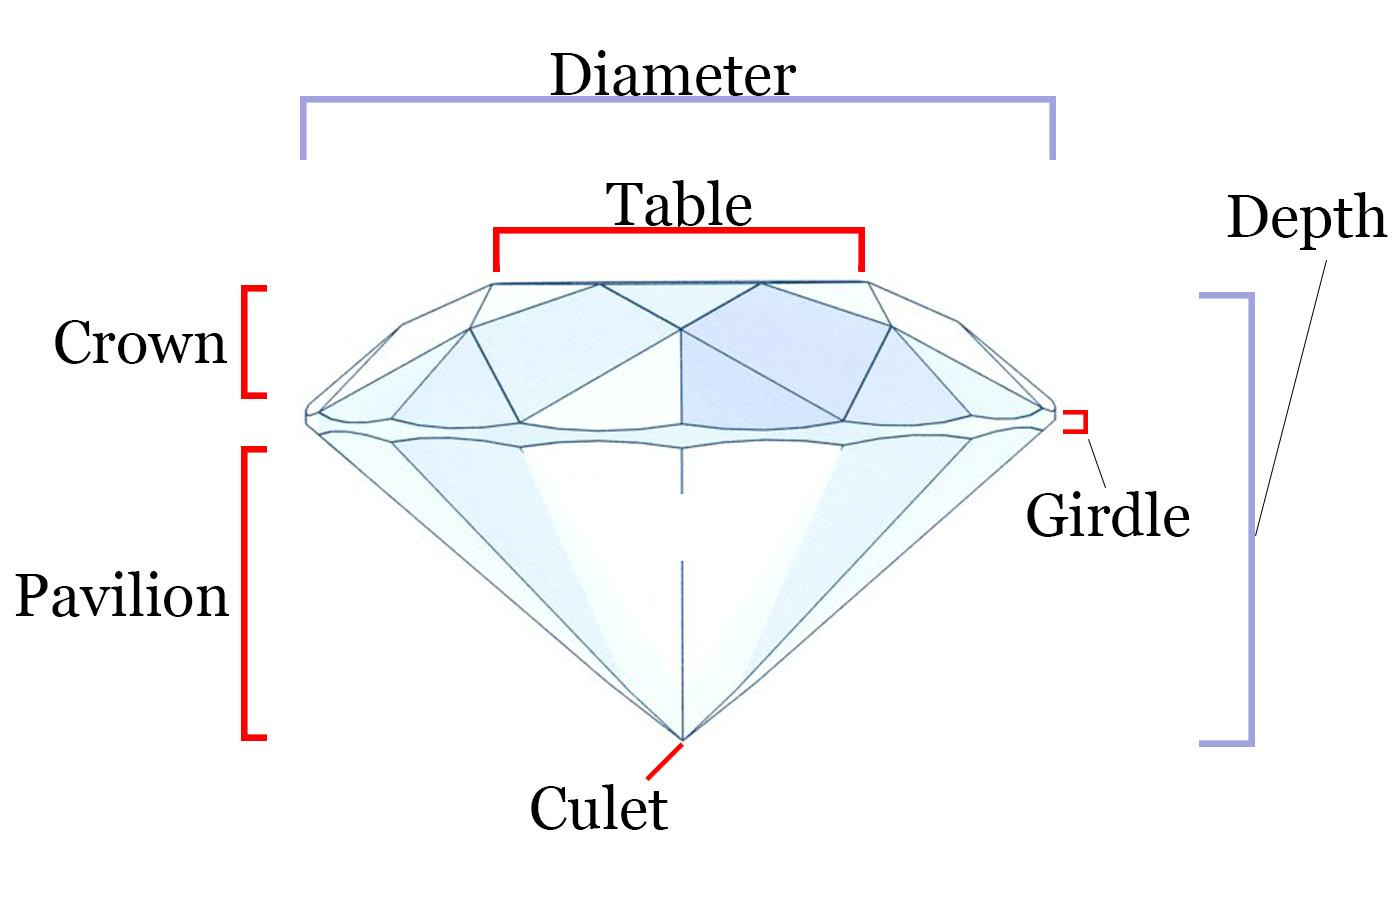

In [3]:
# First look at the data
df_init.head()

Out[3]: 
  diamond_id  carat  depth_pct  ...  height_mm  color_grade  clarity_grade
0   D7-00001   1.51       58.1  ...       4.38            4              4
1   D7-00002   0.33       63.1  ...       2.77            7              3
2   D7-00003   1.01       62.7  ...       3.99            7              3
3   D7-00004   0.71       60.6  ...       3.51            7              3
4   D7-00005   0.31       62.0  ...       2.71            3              5

[5 rows x 10 columns]


In [4]:
# Data shape
print(f"Data shape: {df_init.shape}")

Data shape: (5023, 10)


In [5]:
# Data column statistics
df_init.describe().round(2)

Out[5]: 
         carat  depth_pct  table_pct  ...  height_mm  color_grade  clarity_grade
count  5023.00    4993.00    4993.00  ...    5023.00      5023.00        5023.00
mean      0.87      62.22      58.12  ...       3.65         4.33           3.76
std       0.50       2.28       2.82  ...       0.84         1.71           1.62
min       0.21      50.80      44.00  ...       0.00         1.00           1.00
25%       0.46      61.00      56.00  ...       3.02         3.00           3.00
50%       0.80      62.10      58.00  ...       3.68         4.00           4.00
75%       1.06      63.50      59.00  ...       4.09         6.00           5.00
max       5.01      79.00      95.00  ...      31.80         7.00           8.00

[8 rows x 9 columns]


In [6]:
# Missing values sum per column
print("Missing values amount per column:")
df_init.isna().sum() # The amount of missing values compared to 5023 rows is neglectable

Missing values amount per column:
Out[6]: 
diamond_id        0
carat             0
depth_pct        30
table_pct        30
price_usd         0
length_mm         0
width_mm          0
height_mm         0
color_grade       0
clarity_grade     0
dtype: int64


In [7]:
# Missing values mean per column
print("Missing values rate per column:")
df_init.isna().mean() # The percentage of missing values in the columns is pretty small 

Missing values rate per column:
Out[7]: 
diamond_id       0.000000
carat            0.000000
depth_pct        0.005973
table_pct        0.005973
price_usd        0.000000
length_mm        0.000000
width_mm         0.000000
height_mm        0.000000
color_grade      0.000000
clarity_grade    0.000000
dtype: float64


In [8]:
# Data duplicates
print(f"Amount of duplicated rows: {df_init.duplicated().sum()}")

Amount of duplicated rows: 0


In [9]:
# Identical measurements under different IDs are possible duplicates.
df_duplicates = df_init.drop('diamond_id', axis=1).duplicated()
duplicated_indexes = df_duplicates[df_duplicates]
print(f'Possible duplicate records: {df_duplicates.sum()}')
# Retain the notebook's existing deduplication policy as an explicit assumption.
# Rounded measurements can coincide, so these are not confirmed duplicate stones.

Possible duplicate records: 6


In [10]:
# Checking the describe table, we can see that there are min value in [height, length, width] which is impossible
# Masking rows were one of the paremeters is 0
non_physical_data = df_init[(df_init["length_mm"] == 0) | (df_init["height_mm"] == 0) | (df_init["width_mm"] == 0)]
display(non_physical_data)

print(f"We found {len(non_physical_data)} impossible diamonds.") # We will delete those since there are only 20 out of 5023 rows of data in total


We found 20 impossible diamonds.


,diamond_id,carat,depth_pct,table_pct,price_usd,length_mm,width_mm,height_mm,color_grade,clarity_grade
209,D7-00210,1.56,62.2,54.0,12800,0.00,0.00,0.0,4,4
219,D7-00220,1.00,59.1,59.0,3142,6.55,6.48,0.0,4,2
538,D7-00539,1.10,63.0,59.0,3696,6.50,6.47,0.0,4,2
1232,D7-01233,1.01,58.1,59.0,3167,6.66,6.60,0.0,3,1
1710,D7-01711,1.12,60.4,59.0,2383,6.71,6.67,0.0,4,1
1757,D7-01758,2.25,61.3,58.0,15397,8.52,8.42,0.0,2,3
1867,D7-01868,1.50,64.0,61.0,4731,7.15,7.04,0.0,4,1
2029,D7-02030,1.07,61.6,56.0,4954,0.00,6.62,0.0,5,2
2147,D7-02148,1.00,63.3,53.0,5139,0.00,0.00,0.0,3,4
2405,D7-02406,1.14,57.5,67.0,6381,0.00,0.00,0.0,4,5


## Deleting the duplicates & impossible diamonds

In [11]:
# Dropping impossible values
print(f"Amount of rows before: {df_init.shape[0]}")
df_init = df_init.drop(index = non_physical_data.index)
print(f"Amount of rows after: {df_init.shape[0]}")

Amount of rows before: 5023
Amount of rows after: 5003


In [12]:
# Dropping duplicates using duplicated_indexes we found prior
print(f"Amount of rows before: {df_init.shape[0]}")
df_init = df_init.drop(index = duplicated_indexes.index, errors='ignore')
print(f"Amount of rows after: {df_init.shape[0]}")


Amount of rows before: 5003
Amount of rows after: 4998


## Graphs

In [13]:
df_init

Out[13]: 
     diamond_id  carat  depth_pct  ...  height_mm  color_grade  clarity_grade
0      D7-00001   1.51       58.1  ...       4.38            4              4
1      D7-00002   0.33       63.1  ...       2.77            7              3
2      D7-00003   1.01       62.7  ...       3.99            7              3
3      D7-00004   0.71       60.6  ...       3.51            7              3
4      D7-00005   0.31       62.0  ...       2.71            3              5
...         ...    ...        ...  ...        ...          ...            ...
5018   D7-05019   0.92       62.2  ...       3.86            6              3
5019   D7-05020   0.34       59.0  ...       2.72            5              8
5020   D7-05021   0.32       62.1  ...       2.71            3              6
5021   D7-05022   1.50       64.6  ...       4.61            5              3
5022   D7-05023   0.90       64.4  ...       3.90            5              4

[4998 rows x 10 columns]


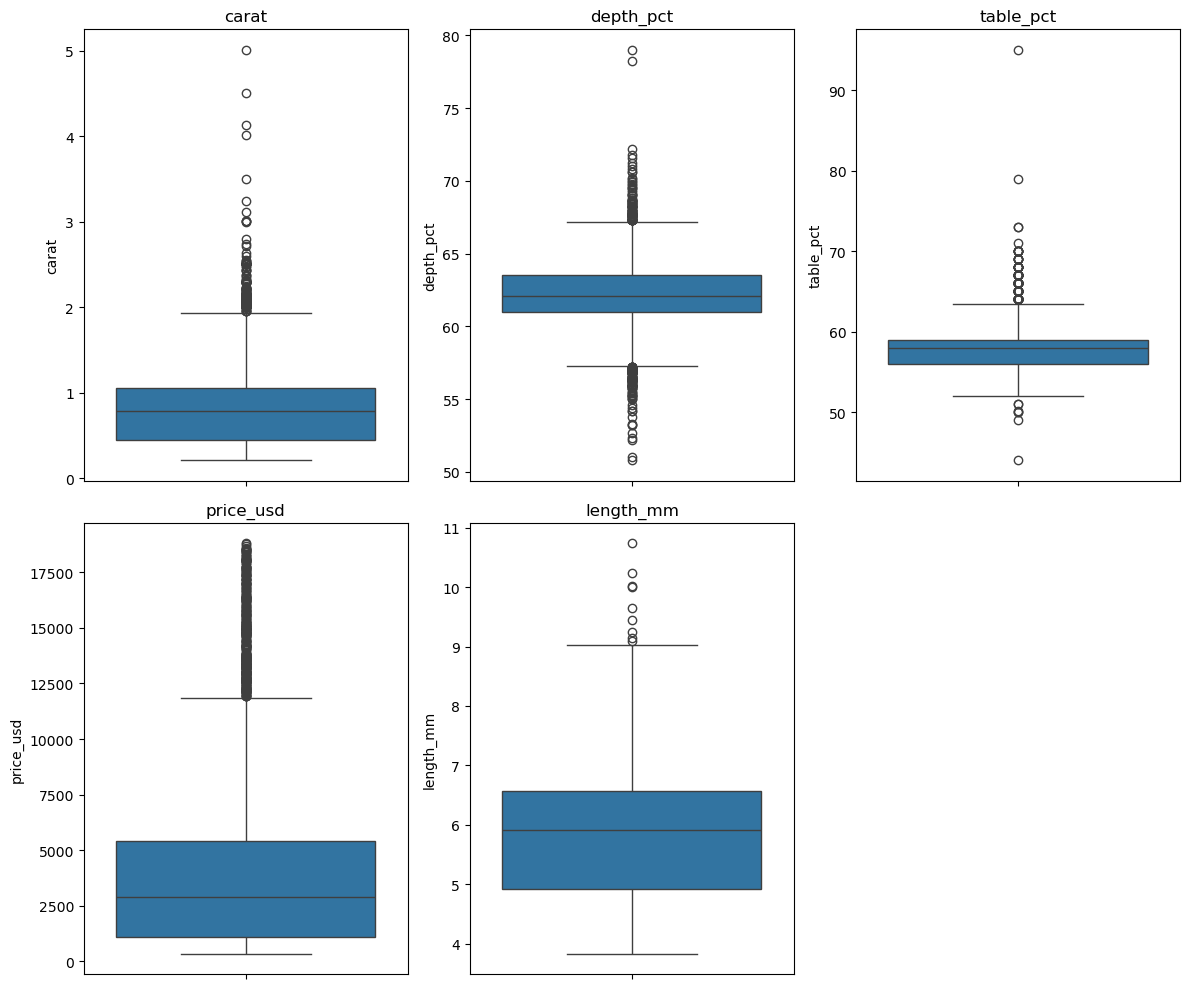

In [14]:
# Vertical boxplot for each numerical column
# Exclude categorical columns
cols = df_init.select_dtypes(include='number').columns.drop(
    ['color_grade', 'clarity_grade', 'height_mm', 'width_mm'], errors='ignore')

zoom_cols = ['width_mm', 'height_mm']
n_cols = (len(cols) + 1) // 2

fig, axes = plt.subplots(2, n_cols, figsize=(4 * n_cols, 10))
axes = axes.flatten()

for col, ax in zip(cols, axes):
    sns.boxplot(data=df_init, y=col, ax=ax)
    ax.set_title(col)

    if col in zoom_cols:
        lower, upper = df_init[col].quantile([0.01, 0.99])
        ax.set_ylim(lower, upper)
        ax.set_title(f'{col} (Zoomed)')

for ax in axes[len(cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

**Graph explanation.** The five panels show carat, depth percentage, table percentage, price, and length. Boxes mark the middle 50% and points beyond whiskers flag distributional extremes. Carat and price show long upper tails.

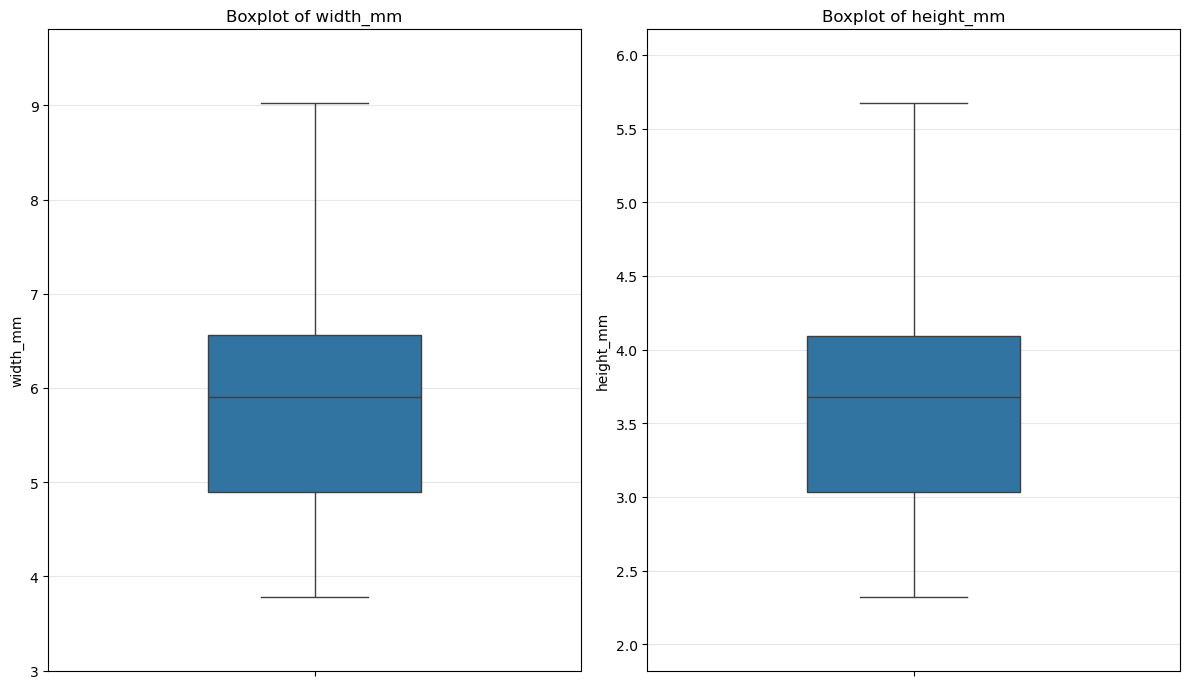

In [15]:
# Boxplots without displaying outliers

zoom_cols = ['width_mm', 'height_mm']

fig, axes = plt.subplots(1, 2, figsize=(12, 7))

for col, ax in zip(zoom_cols, axes):
    sns.boxplot(
        data=df_init,
        y=col,
        ax=ax,
        showfliers=False,
        width=0.4
    )

    ax.set_title(f'Boxplot of {col}')
    ax.margins(y=0.15)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Graph explanation.** These width and height boxplots hide outlier markers with showfliers=False. They show the central spread while extreme measurements remain in the underlying data.

### Boxplot insights

Carat and price have long upper tails. Depth and table percentages have narrower central ranges with observations beyond the whiskers. Width and height are shown separately with outlier markers hidden, so those plots cannot establish the extent of extreme values. Ordinal color and clarity grades are examined with count plots. Large carat or price values can represent legitimate diamonds.

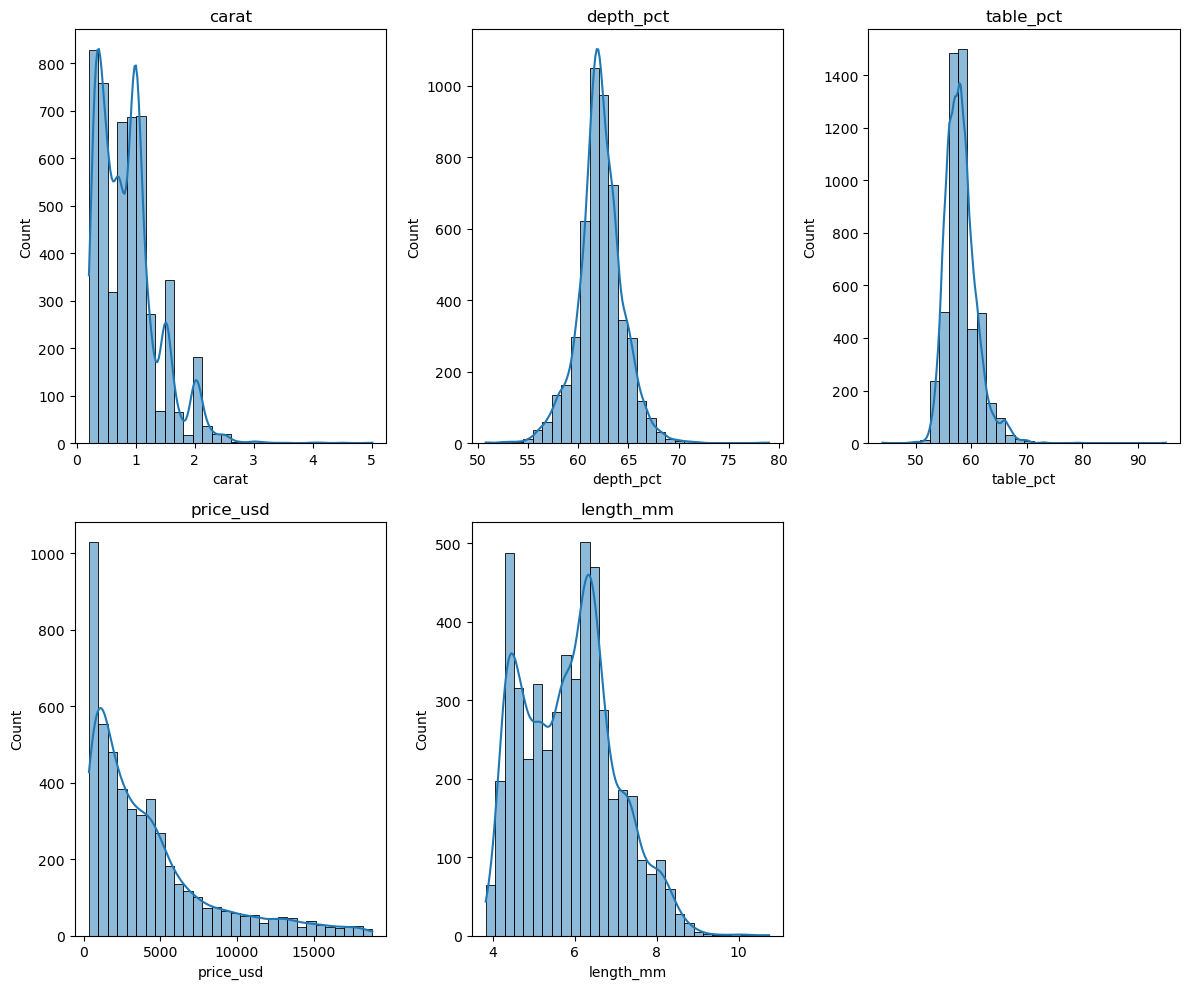

In [16]:
# Histograms with KDE curves arranged in 2 rows

fig, axes = plt.subplots(2, n_cols, figsize=(4 * n_cols, 10))
axes = axes.flatten()

for col, ax in zip(cols, axes):
    data = df_init[col].dropna()

    if col in zoom_cols:
        lower, upper = data.quantile([0.01, 0.99])
        data = data[data.between(lower, upper)]

    sns.histplot(x=data, kde=True, bins=30, ax=ax)
    ax.set_title(f'{col} (Zoomed)' if col in zoom_cols else col)

for ax in axes[len(cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

**Graph explanation.** Histograms show the frequency distributions of carat, depth, table, price, and length. The smooth KDE curves summarize density. Carat and price have long right tails.

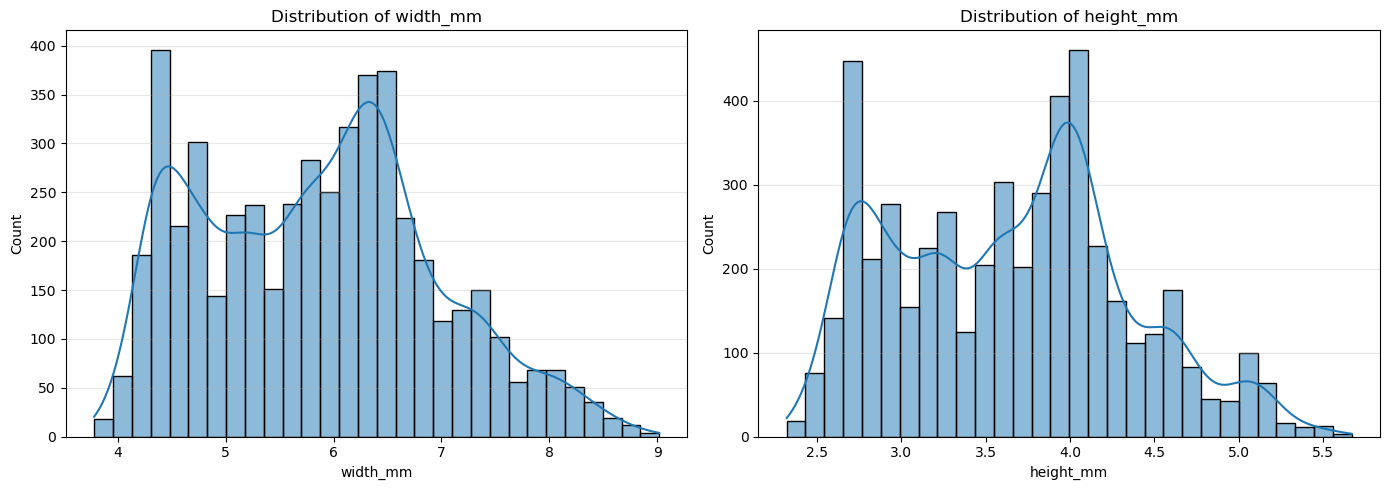

In [17]:
# Histograms with KDE, excluding IQR outliers from visualization

zoom_cols = ['width_mm', 'height_mm']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for col, ax in zip(zoom_cols, axes):
    Q1 = df_init[col].quantile(0.25)
    Q3 = df_init[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    data = df_init[col]
    data = data[data.between(lower, upper)]

    sns.histplot(x=data, kde=True, bins=30, ax=ax)

    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.margins(x=0.05)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Graph explanation.** Width and height histograms show only values within 1.5 IQR of their respective quartiles. This display filter emphasizes the central distributions and does not alter df_init.

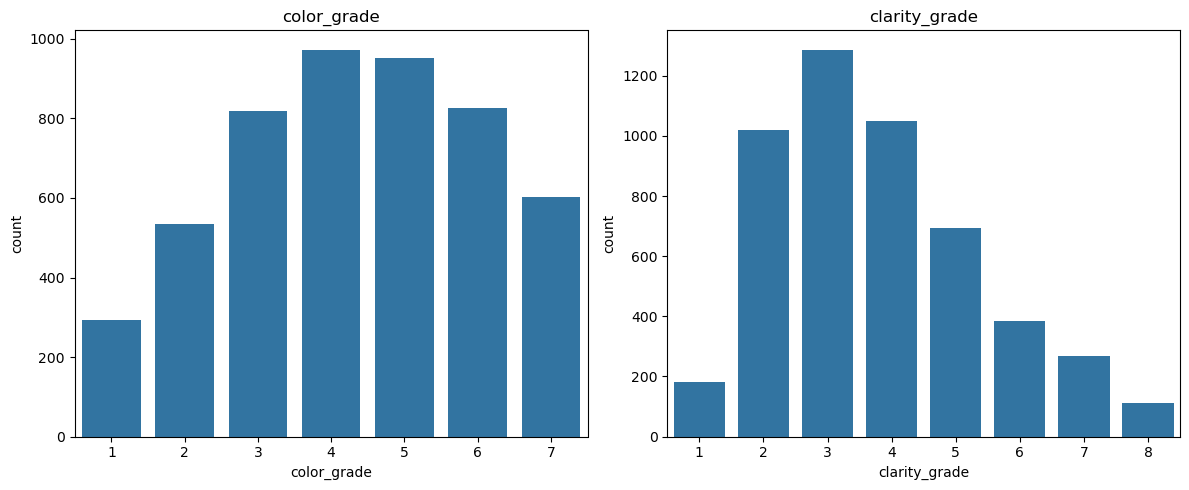

In [18]:
# Countplot for categorical columns

categorical_cols = ['color_grade', 'clarity_grade']



fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for col, ax in zip(categorical_cols, axes):
    sns.countplot(data=df_init, x=col, ax=ax,
                  order=sorted(df_init[col].dropna().unique()))
    ax.set_title(col)

plt.tight_layout()
plt.show()

**Graph explanation.** The two count plots show the frequency of each ordered grade. Color increases from 1=J to 7=D. Clarity increases from 1=I1 through SI2, SI1, VS2, VS1, VVS2, VVS1 to 8=IF.

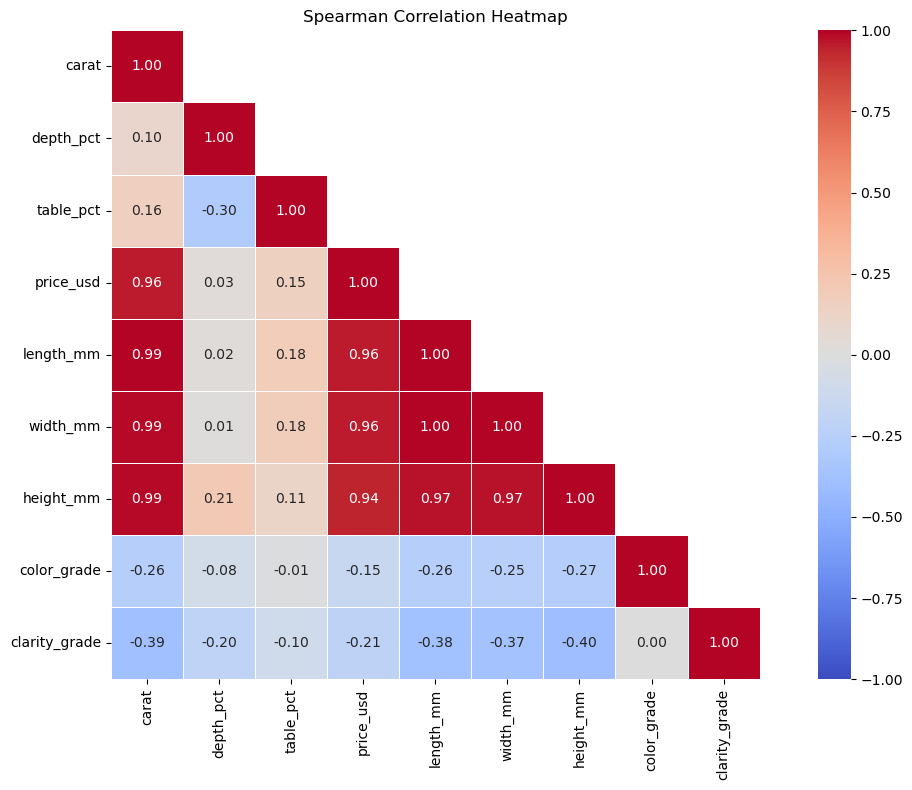

In [19]:
# Spearman correlation including ordinal categorical features

corr = df_init.corr(method='spearman', numeric_only=True)

# Mask the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)

plt.title('Spearman Correlation Heatmap')
plt.tight_layout()
plt.show()

**Graph explanation.** Spearman correlations summarize monotonic associations. Carat and dimensions are strongly related, and price rises strongly with carat. Marginal grade–price correlations combine differences in weight and other features, so they do not estimate an independent quality premium.

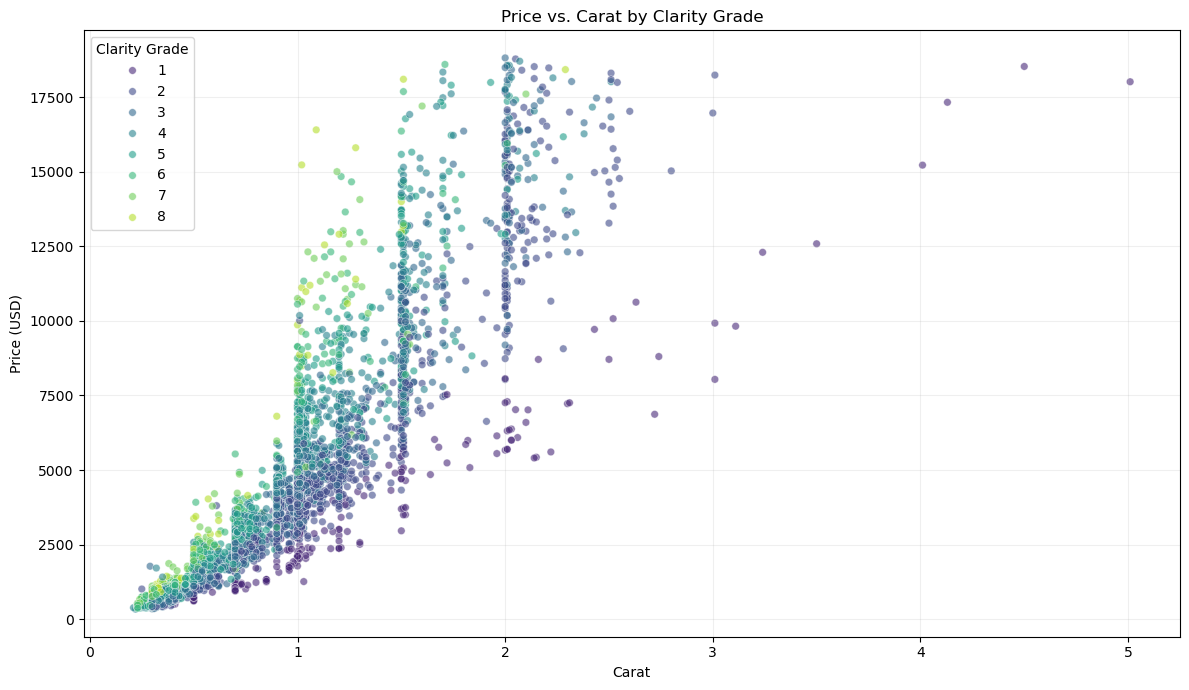

In [20]:
# Price vs. Carat by Clarity Grade

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df_init,
    x='carat',
    y='price_usd',
    hue=df_init['clarity_grade'].astype('category'),
    palette='viridis',
    alpha=0.6,
    s=30
)

plt.title('Price vs. Carat by Clarity Grade')
plt.xlabel('Carat')
plt.ylabel('Price (USD)')
plt.legend(title='Clarity Grade')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Graph explanation.** Each point is a diamond, with clarity indicated by color. Price generally increases with carat, while the vertical spread shows substantial price differences among diamonds of similar weight.

width_mm: 181 rows excluded
height_mm: 233 rows excluded
length_mm: 184 rows excluded


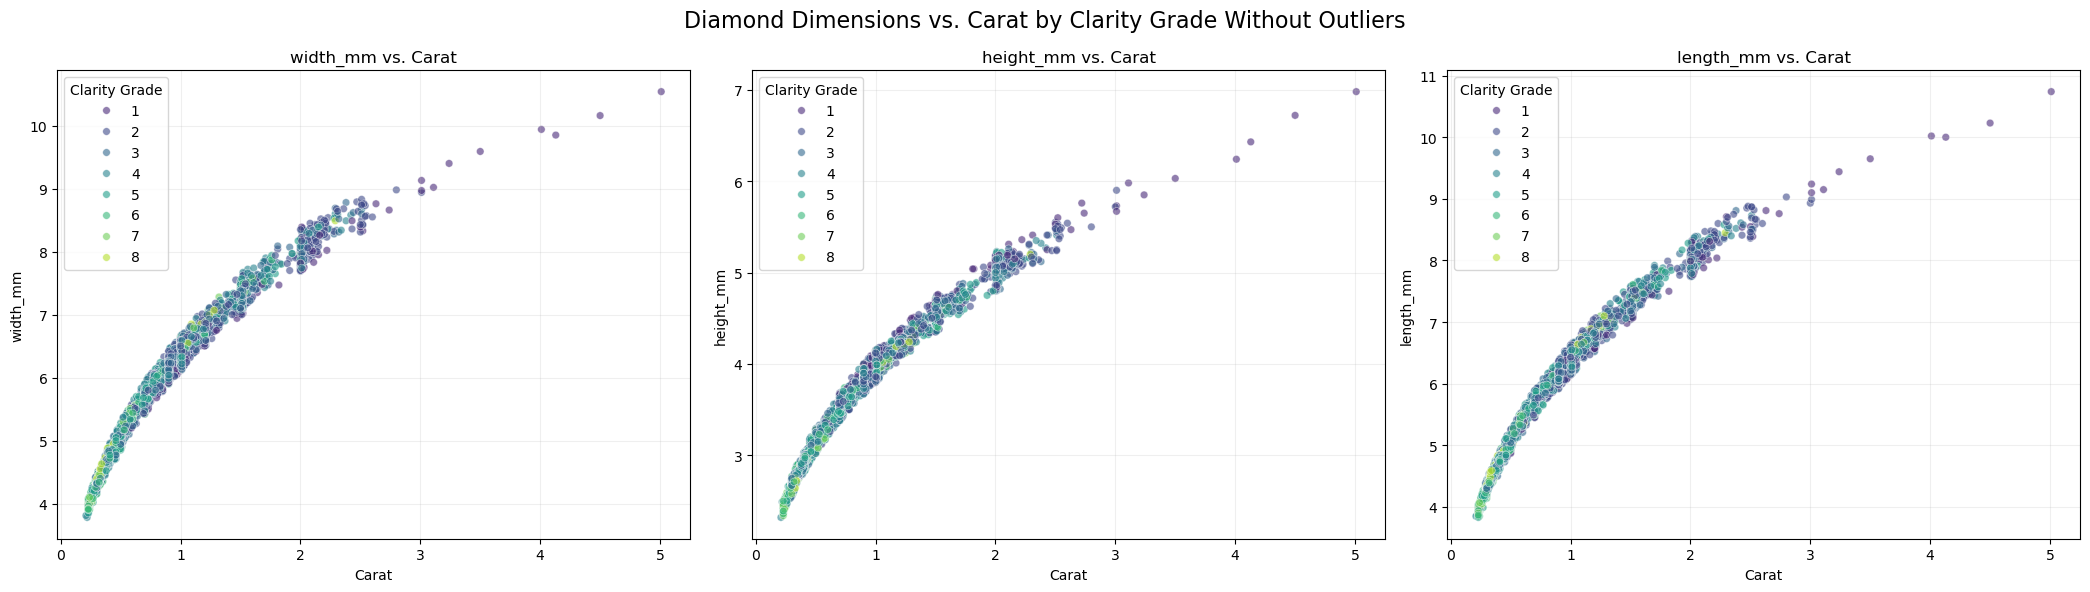

In [21]:
# Diamond dimensions vs. Carat by Clarity Grade without outliers

df_unique = df_init.drop_duplicates()

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

cols = ['width_mm', 'height_mm', 'length_mm']

for col, ax in zip(cols, axes):

    # Normalize dimension relative to diamond weight
    ratio = df_unique[col] / np.cbrt(df_unique['carat'].where(df_unique['carat'] > 0))

    # Calculate IQR boundaries
    Q1 = ratio.quantile(0.25)
    Q3 = ratio.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Exclude outliers
    df_filtered = df_unique[ratio.between(lower, upper)]

    sns.scatterplot(
        data=df_filtered,
        x='carat',
        y=col,
        hue=df_filtered['clarity_grade'].astype('category'),
        hue_order=sorted(df_unique['clarity_grade'].dropna().unique()),
        palette='viridis',
        alpha=0.6,
        s=30,
        ax=ax
    )

    ax.set_title(f'{col} vs. Carat')
    ax.set_xlabel('Carat')
    ax.set_ylabel(col)
    ax.legend(title='Clarity Grade')
    ax.grid(alpha=0.2)

    print(f'{col}: {len(df_unique) - len(df_filtered)} rows excluded')

plt.suptitle('Diamond Dimensions vs. Carat by Clarity Grade Without Outliers',
             fontsize=16)

plt.tight_layout()
plt.show()

**Graph explanation.** Each panel relates one physical dimension to carat. The display removes observations outside 1.5 IQR of that dimension divided by the cube root of carat. Each panel can therefore contain a different subset.

Price generally increases with carat, with considerable variation at similar weights. The scatter plot alone does not establish an exponential functional relationship. Physical dimensions increase with carat along a curved trend consistent with comparing a linear dimension to mass.

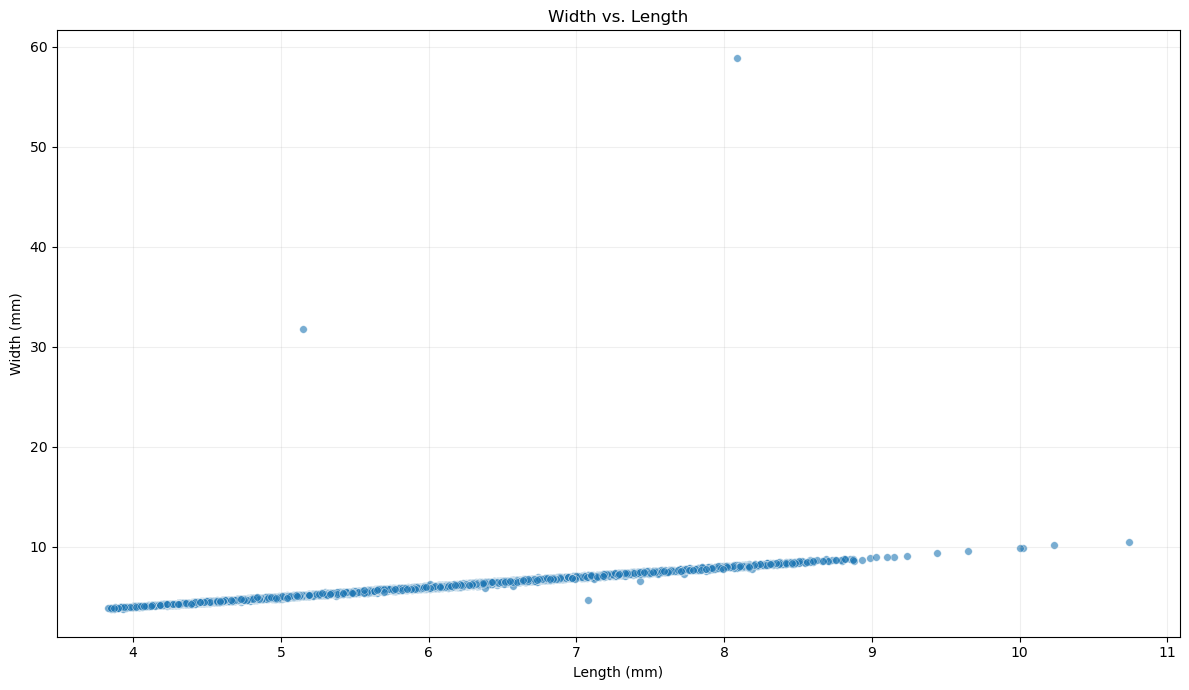

In [22]:
# Width vs. Length

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df_init,
    x='length_mm',
    y='width_mm',
    alpha=0.6,
    s=30
)

plt.title('Width vs. Length')
plt.xlabel('Length (mm)')
plt.ylabel('Width (mm)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Graph explanation.** Most diamonds have similar lengths and widths. Extreme width measurements stretch the vertical scale and warrant inspection. This plot uses one color for every point.

We can see some problematic outliers. Lets see the graph without them!

Outliers excluded: 3


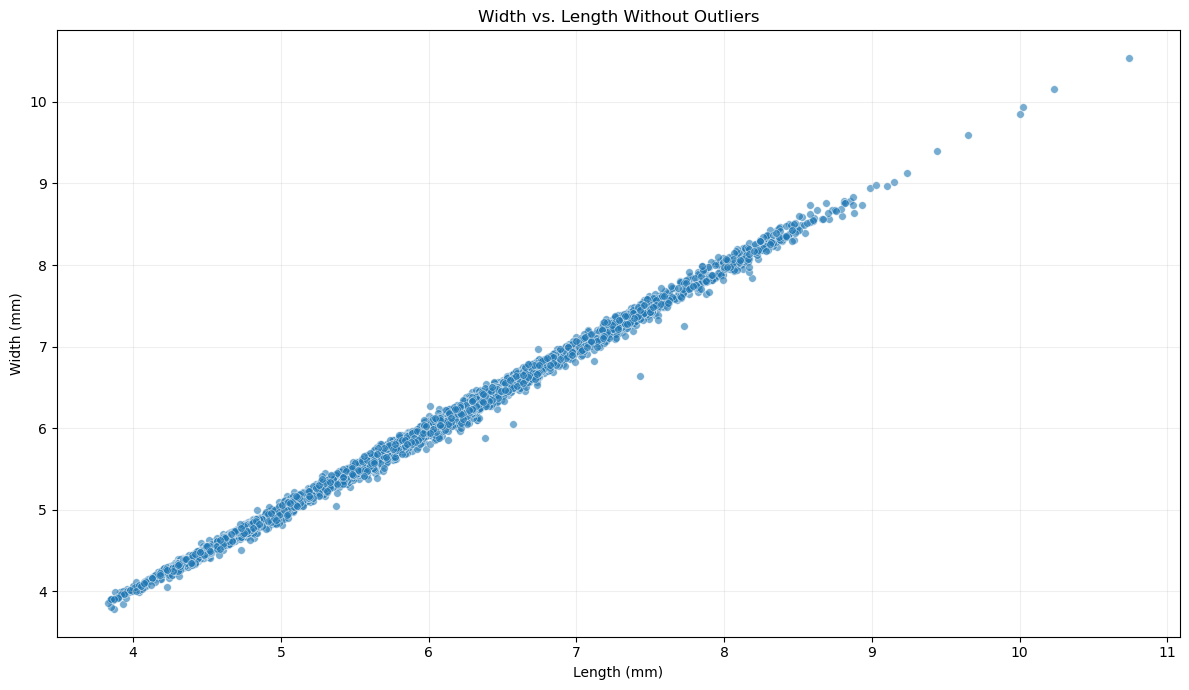

In [23]:
# Width vs. Length without extreme outliers

df_filtered = df_init[
    (df_init['width_mm'] - df_init['length_mm']).abs() <= 1
]

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df_filtered,
    x='length_mm',
    y='width_mm',
    alpha=0.6,
    s=30
)

plt.title('Width vs. Length Without Outliers')
plt.xlabel('Length (mm)')
plt.ylabel('Width (mm)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Outliers excluded: {len(df_init) - len(df_filtered)}")

**Graph explanation.** Restricting the absolute width–length difference to at most 1 mm reveals the strong near-diagonal pattern in the retained subset. The threshold is a display choice rather than a universal physical rule.

Width and length are closely aligned for the displayed diamonds. The filter retains observations whose width and length differ by at most 1 mm, so this graph describes that subset.

In [24]:
# 3D diamond dimensions without outliers

cols = ['length_mm', 'width_mm', 'height_mm']

mask = df_init['carat'] > 0

for col in cols:
    ratio = df_init[col] / np.cbrt(df_init['carat'])

    Q1 = ratio.quantile(0.25)
    Q3 = ratio.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = mask & ratio.between(lower, upper)

df_filtered_3d = df_init[mask]

fig = px.scatter_3d(
    df_filtered_3d,
    x='length_mm',
    y='width_mm',
    z='height_mm',
    color='carat',
    color_continuous_scale='Viridis',
    opacity=0.6,
    title='3D Diamond Dimensions Without Outliers'
)

fig.update_traces(marker=dict(size=3))
fig.update_layout(width=1000, height=700)

fig.show()

print(f"Rows excluded: {len(df_init) - len(df_filtered_3d)}")

Rows excluded: 387


**Graph explanation.** The 3D plot shows length, width, and height together, colored by carat. Dimensions increase together as weight rises. Its carat-adjusted IQR filters select a subset for display.

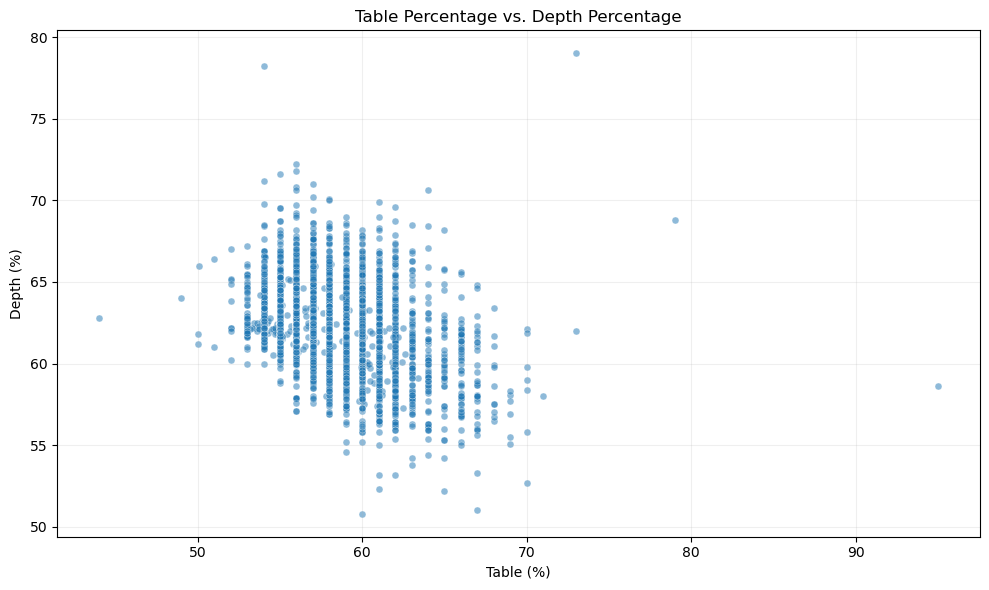

In [25]:
# Table Percentage vs. Depth Percentage

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_init,
    x='table_pct',
    y='depth_pct',
    alpha=0.5,
    s=25
)

plt.title('Table Percentage vs. Depth Percentage')
plt.xlabel('Table (%)')
plt.ylabel('Depth (%)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Graph explanation.** The plot compares table and depth percentages. Their modest negative association indicates that larger table percentages tend to accompany lower depth percentages in this sample.

Table and depth percentages have a negative Spearman association of approximately −0.297 in this EDA dataset. Most points lie in a compact central region. Extreme proportions require investigation before being classified as measurement errors.

color_grade,1,2,3,4,5,6,7
clarity_grade,,,,,,,
1,5322.5,2915.5,2966.0,2375.0,2098.0,2571.0,3819.5
2,4329.0,5407.0,4172.0,4047.0,3783.5,3632.0,3829.5
3,4161.0,4129.0,3753.0,3004.0,2700.0,2265.0,2690.0
4,3501.5,3258.0,4489.0,4022.0,2459.0,1814.0,1838.0
5,3062.0,2788.0,2401.0,2390.0,2381.0,1867.0,1752.0
6,7773.0,2448.0,1162.0,1838.0,2011.5,1013.5,1065.0
7,7670.5,863.0,800.5,1096.0,975.0,1011.0,1323.5
8,1221.0,673.0,1114.0,1056.0,1294.5,2040.5,3446.0


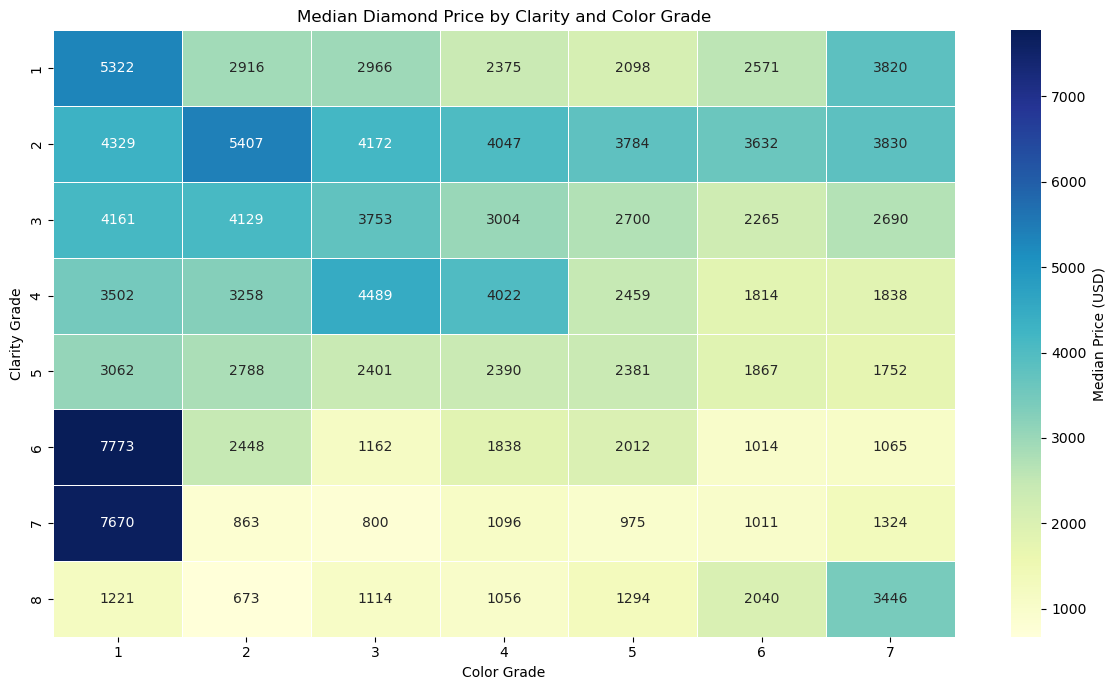

In [26]:
# Median price by clarity grade and color grade

median_price = df_init.groupby(
    ['clarity_grade', 'color_grade']
)['price_usd'].median().unstack()

# Display the matrix
display(median_price)

# Heatmap
plt.figure(figsize=(12, 7))

sns.heatmap(
    median_price,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Median Price (USD)'}
)

plt.title('Median Diamond Price by Clarity and Color Grade')
plt.xlabel('Color Grade')
plt.ylabel('Clarity Grade')
plt.tight_layout()
plt.show()

**Graph explanation.** Each cell is the median price for a clarity–color combination in the EDA data after the initial exclusions. Group sizes and carat distributions vary, so higher quality grades need not have higher unadjusted medians.

In [27]:
# Remove extreme outliers before dimensionality reduction

dimension_cols = ['length_mm', 'width_mm', 'height_mm']
proportion_cols = ['depth_pct', 'table_pct']

# Complete-case exclusion is explicit before applying the outlier rules.
mask = df_init[dimension_cols + proportion_cols + ['carat', 'color_grade', 'clarity_grade']].notna().all(axis=1)
print(f'Rows with missing modeling features: {(~mask).sum()}')

# Carat-adjusted IQR for physical dimensions
for col in dimension_cols:
    ratio = df_init[col] / np.cbrt(df_init['carat'])

    Q1 = ratio.quantile(0.25)
    Q3 = ratio.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 3 * IQR
    upper = Q3 + 3 * IQR

    mask &= ratio.between(lower, upper)

# Regular IQR for percentage features
for col in proportion_cols:
    Q1 = df_init[col].quantile(0.25)
    Q3 = df_init[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 3 * IQR
    upper = Q3 + 3 * IQR

    mask &= df_init[col].between(lower, upper)

# Create the cleaned dataset
df_clean = df_init[mask].copy()

print(f"Rows before outlier removal: {len(df_init)}")
print(f"Rows after outlier removal: {len(df_clean)}")
print(f"Total rows removed: {len(df_init) - len(df_clean)}")
print(f"Percentage retained: {len(df_clean) / len(df_init):.2%}")

Rows with missing modeling features: 60
Rows before outlier removal: 4998
Rows after outlier removal: 4889
Total rows removed: 109
Percentage retained: 97.82%


### Cleaning assumptions

The original policy removes six potential duplicate records with different IDs; one overlaps a zero-dimension exclusion. Matching rounded values do not prove that these are the same stone. After those steps, 4,998 rows remain. The 3-IQR filter removes 109 more rows, including all 60 rows with missing depth or table because comparisons with missing values return False. This is complete-case exclusion, not imputation. The final dataset contains 4,889 rows. Statistical extremes may be valid diamonds, so conclusions apply to this filtered sample.

# Dimensionality reduction

NMF requires a nonnegative input matrix. Min–Max scaling below places each retained feature in [0, 1]. PCA and t-SNE use standardized features. Price and diamond ID are excluded from every fitted representation.

### Choice of dimensionality reduction

PCA is a reasonable baseline because physical dimensions are strongly correlated. NMF provides an additive representation of nonnegative scaled features. t-SNE explores local neighborhoods in two and three dimensions. Correlation alone does not establish which method is best for clustering. That choice requires the downstream clustering comparison.

## PCA

PCA uses eight numeric characteristics after StandardScaler. This gives each original feature unit variance. Keeping ordinal grades as numbers assumes equal spacing between adjacent grades. Four correlated size measurements also give size substantial influence. We use a consistent 95% cumulative-variance threshold.

In [28]:
# Prepare features and exclude the target variable
X = df_clean.drop(columns=['diamond_id', 'price_usd']).select_dtypes(include='number')

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_ * 100
cumulative_variance = np.cumsum(explained_variance)

components = np.arange(1, len(explained_variance) + 1)

# Number of components required to explain 95% of variance
n_components = np.searchsorted(cumulative_variance, 95) + 1

print(f'Original number of features: {X.shape[1]}')
print(f'Components required to explain 95% of variance: {n_components}')

Original number of features: 8
Components required to explain 95% of variance: 5


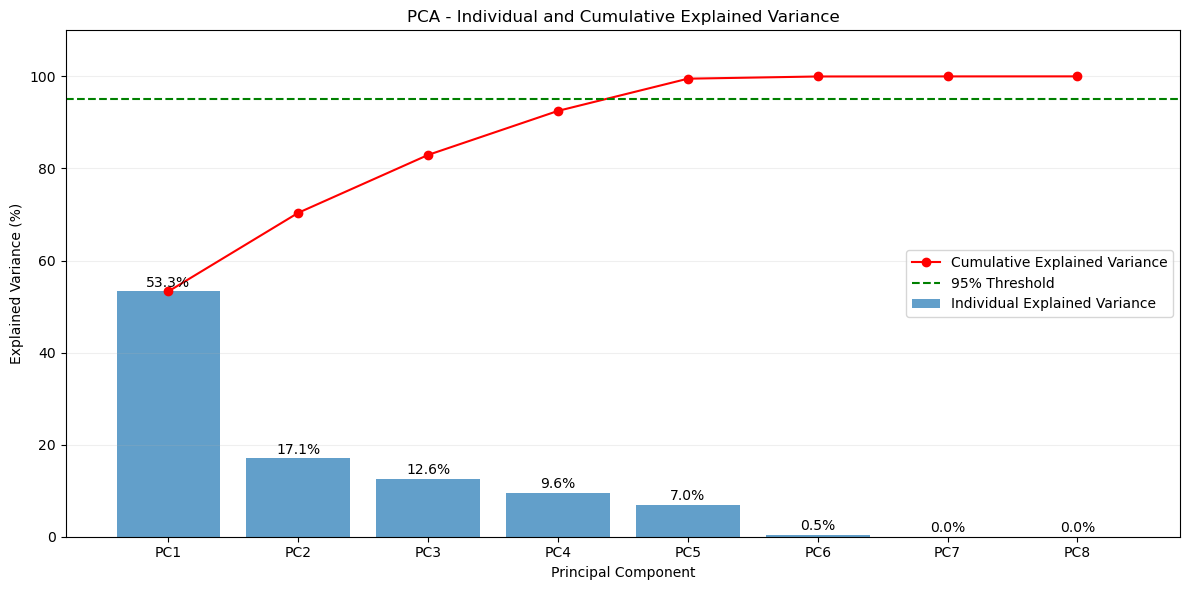

In [29]:
plt.figure(figsize=(12, 6))

plt.bar(
    components,
    explained_variance,
    alpha=0.7,
    label='Individual Explained Variance'
)

plt.plot(
    components,
    cumulative_variance,
    marker='o',
    color='red',
    label='Cumulative Explained Variance'
)

# Display percentage above each bar
for i, value in zip(components, explained_variance):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

# Variance threshold
plt.axhline(y=95, color='green', linestyle='--', label='95% Threshold')

plt.xticks(components, [f'PC{i}' for i in components])
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.title('PCA - Individual and Cumulative Explained Variance')
plt.ylim(0, 110)
plt.legend()
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

**Graph explanation.** Bars show variance explained by individual principal components and the red curve shows the cumulative total. Five components exceed the 95% threshold. All percentages refer to standardized features.

The first five components explain 99.496% of standardized variance. Components 6–8 together explain about 0.504%, which is small but nonzero. Five components are needed to exceed the chosen 95% threshold. Four retain 92.504%.

In [30]:
# Apply PCA with all components
pca_full = PCA()
pca_full.fit(X_scaled)

# Calculate explained variance
explained_variance = pca_full.explained_variance_ratio_ * 100
cumulative_variance = np.cumsum(explained_variance)
components = np.arange(1, len(explained_variance) + 1)

# Select the number of components
threshold = 95
n_components = np.searchsorted(cumulative_variance, threshold) + 1

# Apply PCA with the selected number of components
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

# Create reduced DataFrame
df_pca = pd.DataFrame(
    X_pca,
    columns=[f'PC{i+1}' for i in range(n_components)],
    index=X.index
)

print(f'Original number of features: {X_scaled.shape[1]}')
print(f'Selected components: {n_components}')
print(f'Variance retained: {pca.explained_variance_ratio_.sum():.2%}')
print(f'Dimensionality reduction: {1 - n_components / X_scaled.shape[1]:.2%}')

display(df_pca.head())

Original number of features: 8
Selected components: 5
Variance retained: 99.50%
Dimensionality reduction: 37.50%


,PC1,PC2,PC3,PC4,PC5
0,2.694181,-3.772936,-0.049952,-0.375440,0.867461
1,-2.611080,1.099614,1.447935,0.345362,-0.465614
2,0.645594,0.077038,1.485489,0.815382,0.292131
3,-0.578336,-0.095115,1.305530,1.116727,-0.814174
4,-2.651699,1.015544,-1.205378,-0.010351,-0.871523


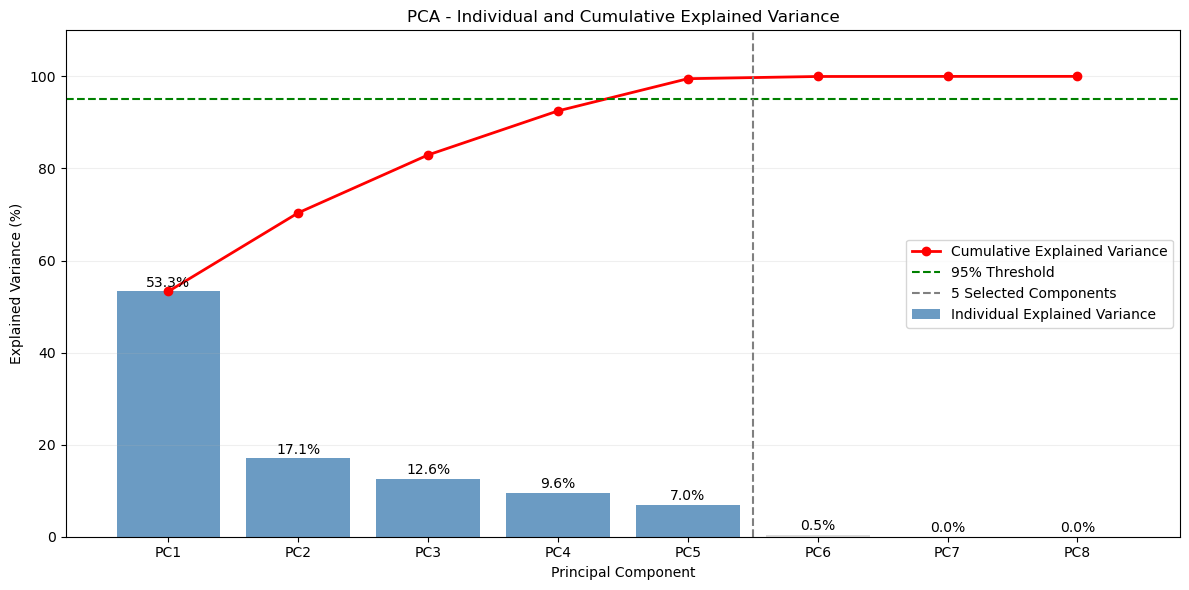

In [31]:
plt.figure(figsize=(12, 6))

# Distinguish retained and discarded components
colors = ['steelblue' if i <= n_components else 'lightgray'
          for i in components]

plt.bar(
    components,
    explained_variance,
    color=colors,
    alpha=0.8,
    label='Individual Explained Variance'
)

plt.plot(
    components,
    cumulative_variance,
    marker='o',
    color='red',
    linewidth=2,
    label='Cumulative Explained Variance'
)

# Display variance above each bar
for i, value in zip(components, explained_variance):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

# Threshold line
plt.axhline(
    y=threshold,
    color='green',
    linestyle='--',
    label=f'{threshold}% Threshold'
)

# Separate retained and discarded components
plt.axvline(
    x=n_components + 0.5,
    color='gray',
    linestyle='--',
    label=f'{n_components} Selected Components'
)

plt.xticks(components, [f'PC{i}' for i in components])
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.title('PCA - Individual and Cumulative Explained Variance')
plt.ylim(0, 110)
plt.legend()
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

**Graph explanation.** Blue bars identify the five retained components under the consistent 95% rule. Together they explain 99.496% of standardized variance. Gray bars account for the remaining 0.504%.

With the consistent 95% threshold, PCA selects five of eight components and retains 99.496% of the standardized variance. This reduces the number of dimensions by 37.5%. Two components retain 70.372% and three retain 82.942%, so low-dimensional plots omit some variation.

## NMF

### NMF 2 and 3-dimensions

In [32]:
# Define nonnegative input before fitting NMF.
nmf_scaler = MinMaxScaler()
X_nmf_scaled = nmf_scaler.fit_transform(X)

# Apply NMF with 2 and 3 components

nmf_results = {}

for k in [2, 3]:

    model = NMF(
        n_components=k,
        init='nndsvda',
        random_state=42,
        max_iter=2000
    )

    X_reduced = model.fit_transform(X_nmf_scaled)

    df_reduced = pd.DataFrame(
        X_reduced,
        columns=[f'NMF{i+1}' for i in range(k)],
        index=X.index
    )

    df_reduced['price_usd'] = df_clean['price_usd']
    df_reduced['clarity_grade'] = df_clean['clarity_grade']
    df_reduced['color_grade'] = df_clean['color_grade']

    nmf_results[k] = df_reduced

    relative_error = (
        model.reconstruction_err_
        / np.linalg.norm(X_nmf_scaled, ord='fro')
    ) * 100

    print(f'NMF with {k} components:')
    print(f'Relative reconstruction error: {relative_error:.2f}%')
    print()

df_nmf_2d = nmf_results[2]
df_nmf_3d = nmf_results[3]

NMF with 2 components:
Relative reconstruction error: 27.59%

NMF with 3 components:
Relative reconstruction error: 18.12%



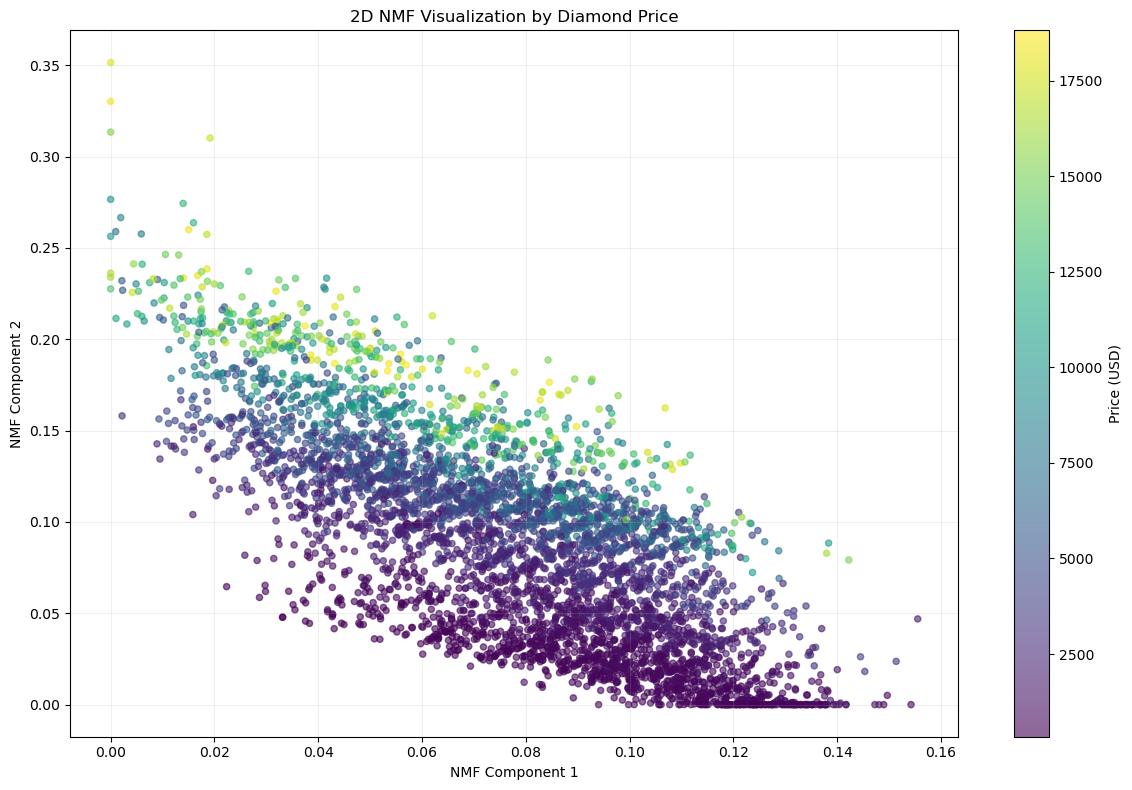

In [33]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df_nmf_2d['NMF1'],
    df_nmf_2d['NMF2'],
    c=df_nmf_2d['price_usd'],
    cmap='viridis',
    alpha=0.6,
    s=20
)

plt.colorbar(scatter, label='Price (USD)')
plt.title('2D NMF Visualization by Diamond Price')
plt.xlabel('NMF Component 1')
plt.ylabel('NMF Component 2')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Graph explanation.** The two coordinates are nonnegative NMF component weights, with price added as color after fitting. The projection has a 27.59% relative reconstruction error. Visible groups have not been tested as clusters.

In [34]:
fig = px.scatter_3d(
    df_nmf_3d,
    x='NMF1',
    y='NMF2',
    z='NMF3',
    color='price_usd',
    color_continuous_scale='Viridis',
    opacity=0.6,
    title='3D NMF Visualization by Diamond Price',
    labels={'price_usd': 'Price (USD)'}
)

fig.update_traces(marker=dict(size=3))
fig.update_layout(width=1000, height=800)

fig.show()

**Graph explanation.** This separately fitted three-component NMF representation has an 18.12% relative reconstruction error. The third axis permits a richer representation, while the price colors help interpret the geometry.

In [35]:
# # Prepare features and exclude the target variable
# X = df_clean.drop(columns=['diamond_id', 'price_usd']).select_dtypes(include='number')

# # Normalize features to the range [0, 1]
# nmf_scaler = MinMaxScaler()
# X_nmf_scaled = nmf_scaler.fit_transform(X)

# # Evaluate different numbers of components
# nmf_components = np.arange(1, X.shape[1] + 1)
# reconstruction_errors = []

# for k in nmf_components:
#     model = NMF(
#         n_components=k,
#         init='nndsvda',
#         random_state=42,
#         max_iter=2000
#     )

#     model.fit(X_nmf_scaled)
#     reconstruction_errors.append(model.reconstruction_err_)

In [36]:
# # Calculate relative reconstruction error (%)
# relative_errors = (
#     np.array(reconstruction_errors)
#     / np.linalg.norm(X_nmf_scaled, ord='fro')
# ) * 100

# # Selected number of components
# nmf_n_components = 5

# plt.figure(figsize=(12, 6))

# plt.plot(
#     nmf_components,
#     relative_errors,
#     marker='o',
#     linewidth=2,
#     color='purple',
#     label='Relative Reconstruction Error'
# )

# # Display percentages above each point
# for k, error in zip(nmf_components, relative_errors):
#     plt.annotate(
#         f'{error:.2f}%',
#         (k, error),
#         xytext=(0, 10),
#         textcoords='offset points',
#         ha='center'
#     )

# # Highlight selected number of components
# plt.axvline(
#     x=nmf_n_components,
#     color='green',
#     linestyle='--',
#     label=f'Selected Components: {nmf_n_components}'
# )

# plt.scatter(
#     nmf_n_components,
#     relative_errors[nmf_components == nmf_n_components],
#     color='green',
#     s=120,
#     zorder=5
# )

# plt.xticks(nmf_components)
# plt.xlabel('Number of Components')
# plt.ylabel('Relative Reconstruction Error (%)')
# plt.title('NMF - Relative Reconstruction Error by Number of Components')
# plt.ylim(bottom=0)
# plt.margins(y=0.15)
# plt.legend()
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

In [37]:
# # Use the same number of components selected by PCA for comparison
# nmf_n_components = n_components

# nmf = NMF(
#     n_components=nmf_n_components,
#     init='nndsvda',
#     random_state=42,
#     max_iter=2000
# )

# X_nmf = nmf.fit_transform(X_nmf_scaled)

# print(f'Original shape: {X.shape}')
# print(f'Reduced shape: {X_nmf.shape}')
# print(f'Reconstruction error: {nmf.reconstruction_err_:.2f}')

The active NMF analysis evaluates two and three components. The commented-out sweep does not supply evidence for an elbow at five components.

In [38]:
# nmf = NMF(
#     n_components=5,
#     init='nndsvda',
#     random_state=42,
#     max_iter=2000
# )

# X_nmf = nmf.fit_transform(X_nmf_scaled)

# df_nmf = pd.DataFrame(
#     X_nmf,
#     columns=[f'NMF{i+1}' for i in range(5)],
#     index=X.index
# )

# display(df_nmf.head())

### NMF results

Recomputed relative Frobenius reconstruction errors are 27.59% for two components and 18.12% for three. Three components reconstruct these Min–Max-scaled features more accurately. These errors are not percentages of unexplained PCA variance. No five-component NMF selection is supported by the active code.

## t-SNE

### t-SNE 2 dimensions

In [39]:
# Prepare features and exclude the target variable
X = df_clean.drop(columns=['diamond_id', 'price_usd']).select_dtypes(include='number')

# Standardize the data
tsne_scaler = StandardScaler()
X_tsne_scaled = tsne_scaler.fit_transform(X)

# Apply t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=42
)

X_tsne = tsne.fit_transform(X_tsne_scaled)

# Create a DataFrame with the reduced features
df_tsne = pd.DataFrame(
    X_tsne,
    columns=['TSNE1', 'TSNE2'],
    index=X.index
)

df_tsne['price_usd'] = df_clean['price_usd']
df_tsne['clarity_grade'] = df_clean['clarity_grade']
df_tsne['color_grade'] = df_clean['color_grade']

print(f'Original shape: {X.shape}')
print(f'Reduced shape: {X_tsne.shape}')
print(f'KL Divergence: {tsne.kl_divergence_:.4f}')

Original shape: (4889, 8)
Reduced shape: (4889, 2)
KL Divergence: 1.4769


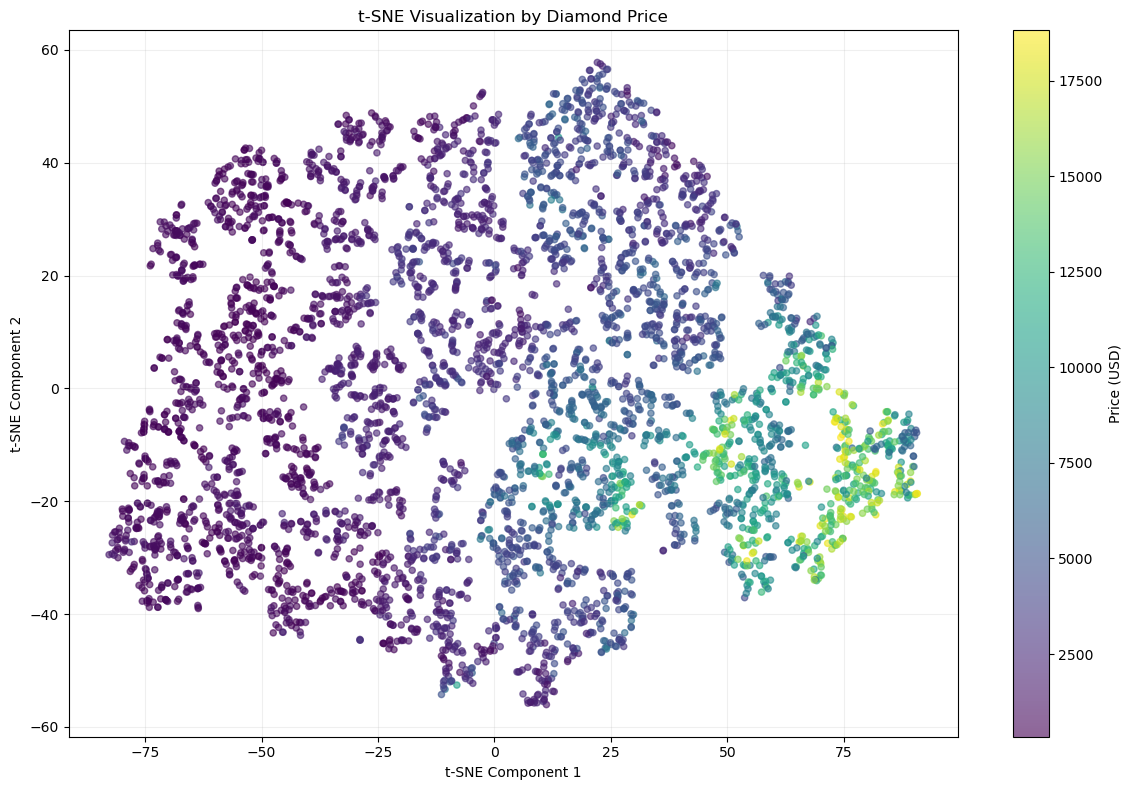

In [40]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df_tsne['TSNE1'],
    df_tsne['TSNE2'],
    c=df_tsne['price_usd'],
    cmap='viridis',
    alpha=0.6,
    s=20
)

plt.colorbar(scatter, label='Price (USD)')
plt.title('t-SNE Visualization by Diamond Price')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Graph explanation.** The 2D t-SNE embedding emphasizes local neighborhoods of standardized characteristics. Price colors provide a descriptive overlay. Orientation and separation between distant islands have no direct physical meaning.

### t-SNE results

The points are positioned using standardized diamond characteristics, and price is added afterward as a color. Similar colors in nearby regions suggest an association between those characteristics and price. Axis directions, distances between distant groups, and visible gaps should not be interpreted as physical quantities or verified clusters. The saved 2D KL divergence is 1.4772. The optimization was rerun during validation; the output above reports the current KL divergence.

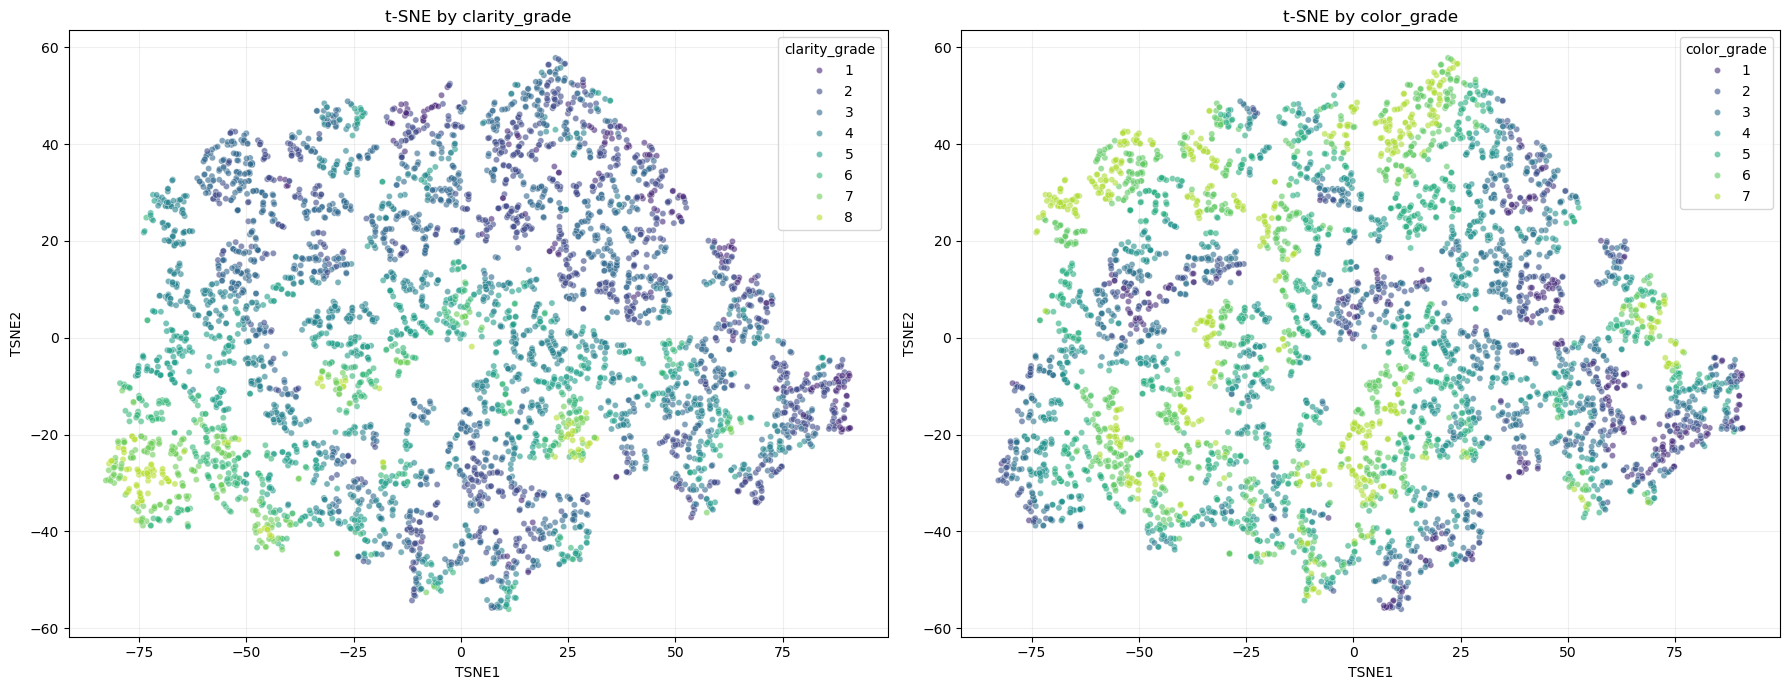

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

cols = ['clarity_grade', 'color_grade']

for col, ax in zip(cols, axes):
    sns.scatterplot(
        data=df_tsne,
        x='TSNE1',
        y='TSNE2',
        hue=df_tsne[col].astype('category'),
        palette='viridis',
        alpha=0.6,
        s=20,
        ax=ax
    )

    ax.set_title(f't-SNE by {col}')
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Graph explanation.** The left panel colors the same embedding by clarity and the right by color grade. Both grades were inputs to t-SNE, so their local separation is not independent validation of the embedding.

### t-SNE 3 dimensions

In [42]:
# Apply t-SNE with 3 components
tsne_3d = TSNE(
    n_components=3,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=42
)

X_tsne_3d = tsne_3d.fit_transform(X_tsne_scaled)

# Create reduced DataFrame
df_tsne_3d = pd.DataFrame(
    X_tsne_3d,
    columns=['TSNE1', 'TSNE2', 'TSNE3'],
    index=X.index
)

# Add original features for visualization
df_tsne_3d['price_usd'] = df_clean['price_usd']
df_tsne_3d['clarity_grade'] = df_clean['clarity_grade']
df_tsne_3d['color_grade'] = df_clean['color_grade']

print(f'Original shape: {X.shape}')
print(f'Reduced shape: {X_tsne_3d.shape}')
print(f'KL Divergence: {tsne_3d.kl_divergence_:.4f}')

Original shape: (4889, 8)
Reduced shape: (4889, 3)
KL Divergence: 1.2499


In [43]:
fig = px.scatter_3d(
    df_tsne_3d,
    x='TSNE1',
    y='TSNE2',
    z='TSNE3',
    color='price_usd',
    color_continuous_scale='Viridis',
    opacity=0.6,
    title='3D t-SNE Visualization by Diamond Price',
    labels={'price_usd': 'Price (USD)'}
)

fig.update_traces(marker=dict(size=3))
fig.update_layout(width=1000, height=800)

fig.show()

**Graph explanation.** The 3D t-SNE embedding is fitted separately from the 2D embedding. Price is an overlay. Rotation helps inspect local neighborhoods, but the extra axis does not establish distinct diamond classes.

In [44]:
for col in ['clarity_grade', 'color_grade']:

    fig = px.scatter_3d(
        df_tsne_3d,
        x='TSNE1',
        y='TSNE2',
        z='TSNE3',
        color=df_tsne_3d[col].astype(str),
        color_discrete_sequence=px.colors.qualitative.Set2,
        opacity=0.6,
        title=f'3D t-SNE Visualization by {col}',
        labels={'color': col}
    )

    fig.update_traces(marker=dict(size=3))
    fig.update_layout(width=1000, height=800)

    fig.show()

**Graph explanation.** The first 3D plot colors the embedding by clarity and the second by color grade. Both overlays describe how input grades are arranged locally. Repeated colors and apparent gaps should be interpreted alongside quantitative cluster evaluation.

## Dimensionality reduction conclusion

| Method | Dimensions | Result | Interpretation |
|---|---|---|---|
| PCA | 5 of 8 | 99.496% variance retained | Meets the chosen 95% threshold |
| NMF | 2 and 3 | 27.59% and 18.12% relative reconstruction error | Three components improve reconstruction |
| t-SNE | 2 and 3 | Saved KL divergences 1.4772 and 1.2503 | Local-neighborhood visualizations |

PCA and NMF values were independently recomputed using the notebook’s retained 4,889 records. Both t-SNE optimizations were rerun and their outputs regenerated. Its lower saved 3D KL divergence does not establish better clustering. PCA with five components is a justified candidate for the clustering stage. The clustering sections below are still empty, so no K-Means or DBSCAN results or algorithm selection have been verified. The price patterns are descriptive and do not isolate the effect of quality at equal carat weight.

# Clustering

## K-Means

## DBSCAN